In [1]:
import gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical

In [10]:
import random
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

In [11]:
class ActorCritic(nn.Module):
    def __init__(self, state_dim, action_dim, hidden_size=512):
        super(ActorCritic, self).__init__()
        # Shared layer
        self.fc = nn.Linear(state_dim, hidden_size)
        
        # Policy (actor) head
        self.policy = nn.Linear(hidden_size, action_dim)
        
        # Value (critic) head
        self.value = nn.Linear(hidden_size, 1)

    def forward(self, x):
        x = torch.tanh(self.fc(x))
        policy_logits = self.policy(x)
        value = self.value(x)
        return policy_logits, value

In [12]:
def compute_returns_and_advantages(rewards, values, dones, gamma, lam):
    advantages = []
    gae = 0
    values = values + [0]  # Add a dummy for bootstrap
    
    for t in reversed(range(len(rewards))):
        delta = rewards[t] + gamma * values[t+1] * (1 - dones[t]) - values[t]
        gae = delta + gamma * lam * (1 - dones[t]) * gae
        advantages.insert(0, gae)
    returns = [adv + val for adv, val in zip(advantages, values[:-1])]
    return advantages, returns


In [13]:
def ppo_update(model, optimizer, states, actions, log_probs_old, returns, advantages, clip_eps):
    states = torch.tensor(states, dtype=torch.float32)
    actions = torch.tensor(actions, dtype=torch.int64)
    log_probs_old = torch.tensor(log_probs_old, dtype=torch.float32)
    returns = torch.tensor(returns, dtype=torch.float32)
    advantages = torch.tensor(advantages, dtype=torch.float32)
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    policy_logits, values = model(states)
    dist = Categorical(logits=policy_logits)
    log_probs_new = dist.log_prob(actions)
    ratio = torch.exp(log_probs_new - log_probs_old)

    # Clipped surrogate objective
    clipped = torch.clamp(ratio, 1 - clip_eps, 1 + clip_eps) * advantages
    actor_loss = -torch.min(ratio * advantages, clipped).mean()

    # Critic loss (MSE)
    critic_loss = nn.MSELoss()(values.squeeze(), returns)

    # Total loss
    # loss = actor_loss + 0.5 * critic_loss
    entropy = dist.entropy().mean()
    loss = actor_loss + 0.5 * critic_loss - 0.01 * entropy

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()


In [14]:
import os
import csv
# Train function returning rewards
def train_ppo(model, optimizer, env, max_env_steps, batch_size, gamma, lambda_, clip_eps, run_id, csv_path):
    # reward_per_episode = []
    # env_steps = []
    step_counter = 0
    episode_idx = 0
    while step_counter < max_env_steps:
        states, actions, rewards, dones, log_probs, values = [], [], [], [], [], []
        state, _ = env.reset()
        ep_reward = 0

        while True:
            state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0)
            logits, value = model(state_tensor)
            dist = Categorical(logits=logits)
            action = dist.sample()

            next_state, reward, terminated, truncated, _ = env.step(action.item())
            done = terminated or truncated

            states.append(state)
            actions.append(action.item())
            rewards.append(reward)
            dones.append(done)
            log_probs.append(dist.log_prob(action).item())
            values.append(value.item())

            state = next_state
            ep_reward += reward
            step_counter +=1
            if done or step_counter >= max_env_steps:
                break

        advantages, returns = compute_returns_and_advantages(rewards, values, dones, gamma, lambda_)
        ppo_update(model, optimizer, states, actions, log_probs, returns, advantages, clip_eps)
        #reward_per_episode.append(ep_reward)
        #env_steps.append(step_counter)
        #print(f"Step {step_counter}/{max_env_steps} | Reward: {ep_reward}")

        with open(csv_path, mode='a', newline='') as file:
            writer = csv.writer(file)
            writer.writerow([run_id, step_counter, max_env_steps, ep_reward])

        print(f"[Run {run_id}] Step {step_counter}/{max_env_steps} | Episode {episode_idx} | Reward: {ep_reward}")
        episode_idx += 1

In [15]:
import csv
import os


config = {
    'learning_rate': 1e-3,
    'batch_size': 3000,
    'gamma': 0.99,
    'lambda': 0.95,
    'clip_eps': 0.4
}

csv_path = "ppo_results.csv"
# # Write header only if the file doesn't exist
if not os.path.exists(csv_path):
    with open(csv_path, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Run", "EnvStep", "TotalSteps", "EpisodeReturn"])

MAX_ENV_STEPS = int(1e6)  # cast to int
REPEATS = 5
results = []

for rep in range(REPEATS):
    print(f"\n=== Run {rep+1}/{REPEATS} ===")
    seed = 42 + rep
    set_seed(seed)

    env = gym.make("CartPole-v1")
    env.reset(seed=seed)

    state_dim = env.observation_space.shape[0]
    action_dim = env.action_space.n

    model = ActorCritic(state_dim, action_dim)
    optimizer = optim.Adam(model.parameters(), lr=config['learning_rate'])

    train_ppo(
        model=model,
        optimizer=optimizer,
        env=env,
        max_env_steps=MAX_ENV_STEPS,
        batch_size=config['batch_size'],
        gamma=config['gamma'],
        lambda_=config['lambda'],
        clip_eps=config['clip_eps'],
        run_id = rep+1,
        csv_path=csv_path
    )


    # # Save result after each run
    # with open(csv_path, mode='a', newline='') as file:
    #     writer = csv.writer(file)
    #     writer.writerow([rep + 1, seed, episode_return, env_step])



=== Run 1/5 ===
[Run 1] Step 81/1000000 | Episode 0 | Reward: 81.0
[Run 1] Step 97/1000000 | Episode 1 | Reward: 16.0
[Run 1] Step 129/1000000 | Episode 2 | Reward: 32.0
[Run 1] Step 142/1000000 | Episode 3 | Reward: 13.0
[Run 1] Step 150/1000000 | Episode 4 | Reward: 8.0
[Run 1] Step 165/1000000 | Episode 5 | Reward: 15.0
[Run 1] Step 179/1000000 | Episode 6 | Reward: 14.0
[Run 1] Step 190/1000000 | Episode 7 | Reward: 11.0
[Run 1] Step 202/1000000 | Episode 8 | Reward: 12.0
[Run 1] Step 217/1000000 | Episode 9 | Reward: 15.0
[Run 1] Step 236/1000000 | Episode 10 | Reward: 19.0
[Run 1] Step 253/1000000 | Episode 11 | Reward: 17.0
[Run 1] Step 281/1000000 | Episode 12 | Reward: 28.0
[Run 1] Step 296/1000000 | Episode 13 | Reward: 15.0
[Run 1] Step 307/1000000 | Episode 14 | Reward: 11.0
[Run 1] Step 322/1000000 | Episode 15 | Reward: 15.0
[Run 1] Step 340/1000000 | Episode 16 | Reward: 18.0
[Run 1] Step 370/1000000 | Episode 17 | Reward: 30.0
[Run 1] Step 382/1000000 | Episode 18 | Re

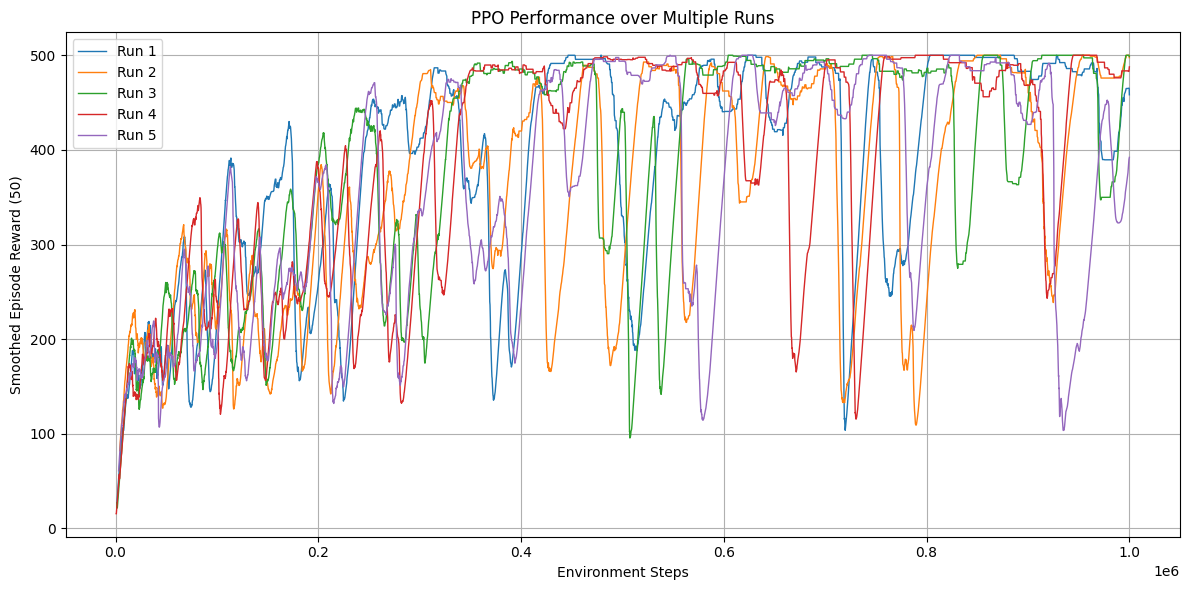

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load data from CSV
csv_path = "ppo_results.csv"
df = pd.read_csv(csv_path)

# Set smoothing window
window_size = 50

# Set up plot
plt.figure(figsize=(12, 6))

# Iterate over all unique runs in the CSV
for i, run_id in enumerate(sorted(df['Run'].unique())):
    run_df = df[df['Run'] == run_id].sort_values(by='EnvStep')
    episode_return = run_df['EpisodeReturn'].values
    env_step = run_df['EnvStep'].values

    # Smooth and align episode return
    if len(episode_return) >= window_size:
        episode_return_smooth = np.convolve(episode_return, np.ones(window_size) / window_size, mode='valid')
        env_step_aligned = env_step[window_size - 1:]
    else:
        episode_return_smooth = episode_return
        env_step_aligned = env_step

    # Plot the smoothed data
    plt.plot(env_step_aligned, episode_return_smooth, label=f'Run {run_id}', linewidth=1)

# Plot formatting
plt.xlabel('Environment Steps')
plt.ylabel(f'Smoothed Episode Reward ({window_size})')
plt.title('PPO Performance over Multiple Runs')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [17]:
!pip install pandas

  Using cached pandas-2.2.3-cp310-cp310-win_amd64.whl.metadata (19 kB)
Using cached pandas-2.2.3-cp310-cp310-win_amd64.whl (11.6 MB)

   ---------------------------------------- 0/3 [pytz]
   ---------------------------------------- 0/3 [pytz]
   ---------------------------------------- 0/3 [pytz]
   ------------- -------------------------- 1/3 [tzdata]
   ------------- -------------------------- 1/3 [tzdata]
   ------------- -------------------------- 1/3 [tzdata]
   ------------- -------------------------- 1/3 [tzdata]
   ------------- -------------------------- 1/3 [tzdata]
   -------------------------- ------------- 2/3 [pandas]
   -------------------------- ------------- 2/3 [pandas]
   -------------------------- ------------- 2/3 [pandas]
   -------------------------- ------------- 2/3 [pandas]
   -------------------------- ------------- 2/3 [pandas]
   -------------------------- ------------- 2/3 [pandas]
   -------------------------- ------------- 2/3 [pandas]
   --------------


[notice] A new release of pip is available: 25.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip
